# Notebook 07: Eyes-closed vs. eyes-open alpha (Berger-effect validity check)

This notebook is a **data-validity check**, not a hypothesis test about sex. It asks whether the device-derived band power behaves the way real EEG must behave, and whether the task labels and timestamps line up with the underlying recording.

The Berger effect is one of the most robust phenomena in electroencephalography: closing the eyes sharply increases alpha power, with the increase largest over posterior (occipital) sites. The task battery contains the ideal within-subject contrast — the same motor task performed with eyes open and with eyes closed — so the manipulation is isolated to eye closure.

**Three predictions, in descending order of importance:**

1. Occipital (O1/O2) alpha power is higher with eyes closed than eyes open, across participants.
2. The increase is larger at O1/O2 than at anterior frontal sites (AF3/AF4) — i.e. it is topographically posterior.
3. The increase is larger in alpha than in the other four bands — i.e. it is spectrally specific.

**If all three hold**, the consumer-grade band power is capturing genuine posterior alpha and the task labelling is sound. **If prediction 1 fails**, there is a data-quality or labelling problem that must be resolved before any other analysis in this project can be trusted.

**Inputs:**
- `data/eeg_features/BA*/2_emotiv_fft_values.csv`
- `data/stimuli.csv` (task list only)
- `outputs/nmf_W.csv` (participant roster only, to match the analysed cohort)

**Outputs:**
- `outputs/berger_per_participant.csv` — per-participant deltas
- `outputs/berger_tests.csv` — all Wilcoxon tests
- `outputs/berger_check.png`
- `outputs/berger_summary.txt`

## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import re
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
EEG_DIR = DATA_DIR / "eeg_features"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
POW_COLS = [f"POW.{ch}.{band}" for ch in CHANNELS for band in FREQ_BANDS]

# Site groupings for the topographic contrast
OCCIPITAL = ["O1", "O2"]
ANTERIOR_FRONTAL = ["AF3", "AF4"]

ALPHA_ALPHA = 0.05   # significance level for the FDR pass across bands

report = []
def log(msg=""):
    print(msg)
    report.append(str(msg))

## Detect eyes-open / eyes-closed task pairs

Rather than hard-coding task names, we parse `stimuli.csv` for tasks whose names encode an eye state and group them into pairs that differ *only* in that state. The detected pairing is printed for inspection — check it before proceeding.

If the detection misses a pair or invents one, set `MANUAL_PAIRS` in the following cell to override it entirely.

In [2]:
stimuli = pd.read_csv(DATA_DIR / "stimuli.csv")
TASKS = stimuli["original_stimuli_name"].astype(str).tolist()

def eye_state(task):
    """Return 'closed', 'open', or None for a task name."""
    t = task.lower()
    if "closed" in t or re.search(r"_ce($|_)", t):
        return "closed"
    if re.search(r"(^|_)open($|_)", t) or t.endswith("open") or re.search(r"_oe($|_)", t):
        return "open"
    return None

def pair_key(task):
    """Strip the eye-state token so that a pair collapses to a common key."""
    t = task.lower()
    for pat in [r"_?closed_?eyes?", r"_?open_?eyes?", r"_?eyes?_?closed",
                r"_?eyes?_?open", r"_?closed", r"_?open", r"_?ce\b", r"_?oe\b"]:
        t = re.sub(pat, "", t)
    return t.strip("_")

detected = {}
for task in TASKS:
    st = eye_state(task)
    if st is None:
        continue
    key = pair_key(task)
    detected.setdefault(key, {})
    detected[key].setdefault(st, []).append(task)

log("Tasks carrying an eye-state token:")
for key, states in sorted(detected.items()):
    log(f"  base '{key}': " + ", ".join(f"{s}={v}" for s, v in sorted(states.items())))

PAIRS = {k: (v["open"][0], v["closed"][0])
         for k, v in detected.items()
         if "open" in v and "closed" in v and len(v["open"]) == 1 and len(v["closed"]) == 1}

unpaired = {k: v for k, v in detected.items() if k not in PAIRS}
log(f"\nComplete open/closed pairs detected: {len(PAIRS)}")
for k, (o, c) in sorted(PAIRS.items()):
    log(f"  {k:25s}  open='{o}'   closed='{c}'")
if unpaired:
    log(f"\n[CHECK] {len(unpaired)} eye-state task(s) without a complete pair — excluded:")
    for k, v in sorted(unpaired.items()):
        log(f"  {k}: {v}")

Tasks carrying an eye-state token:
  base 'gyrus_left': closed=['gyrus_left_closed_eyes'], open=['gyrus_left_open']
  base 'gyrus_right': closed=['gyrus_right_closed_eyes'], open=['gyrus_right_open']

Complete open/closed pairs detected: 2
  gyrus_left                 open='gyrus_left_open'   closed='gyrus_left_closed_eyes'
  gyrus_right                open='gyrus_right_open'   closed='gyrus_right_closed_eyes'


In [3]:
# >>> OVERRIDE HERE IF THE DETECTION ABOVE IS WRONG <<<
# Format: {"label": ("task_name_eyes_open", "task_name_eyes_closed"), ...}
MANUAL_PAIRS = None

if MANUAL_PAIRS is not None:
    PAIRS = dict(MANUAL_PAIRS)
    log("\n[OVERRIDE] Using manually specified pairs:")
    for k, (o, c) in PAIRS.items():
        log(f"  {k:25s}  open='{o}'   closed='{c}'")

if len(PAIRS) == 0:
    raise RuntimeError(
        "No eyes-open/eyes-closed task pairs identified. Set MANUAL_PAIRS explicitly — "
        "this check cannot run without at least one pair."
    )

# Verify every named task actually exists in stimuli.csv
for label, (t_open, t_closed) in PAIRS.items():
    for t in (t_open, t_closed):
        if t not in TASKS:
            raise ValueError(f"Task '{t}' (pair '{label}') is not present in stimuli.csv")
log(f"\nProceeding with {len(PAIRS)} pair(s).")


Proceeding with 2 pair(s).


## Extract per-participant, per-task spectral medians

For each participant and each task in a pair, we take the median across all time-window rows for every (channel × band) feature — the same aggregation used in Notebook 01, but at the level of the individual task rather than the lobe category.

We restrict to the participants who entered the main analysis (the `nmf_W.csv` roster), so that a positive result here licenses the rest of the pipeline on exactly the same cohort.

In [4]:
W = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
COHORT = list(W.index)
log(f"Analysed cohort: {len(COHORT)} participants")

def ba_sort_key(p):
    m = re.match(r"BA(\d+)", p.name)
    return int(m.group(1)) if m else 99999

participant_folders = sorted(
    [p for p in EEG_DIR.iterdir() if p.is_dir() and re.match(r"BA\d+", p.name)],
    key=ba_sort_key,
)

tasks_needed = sorted({t for pair in PAIRS.values() for t in pair})

# task_vectors[task][pid] = Series indexed by POW_COLS
task_vectors = {t: {} for t in tasks_needed}
skipped = []

for folder in participant_folders:
    pid = folder.name
    if pid not in COHORT:
        continue
    fpath = folder / "2_emotiv_fft_values.csv"
    if not fpath.exists():
        skipped.append((pid, "no fft file"))
        continue
    df = pd.read_csv(fpath)
    if "task_name" not in df.columns:
        skipped.append((pid, "no task_name column"))
        continue
    missing = [c for c in POW_COLS if c not in df.columns]
    if missing:
        skipped.append((pid, f"missing {len(missing)} power columns"))
        continue
    for task in tasks_needed:
        sub = df[df["task_name"] == task]
        if len(sub) == 0:
            continue
        task_vectors[task][pid] = sub[POW_COLS].median()

log("\nPer-task coverage within the cohort:")
for task in tasks_needed:
    n = len(task_vectors[task])
    flag = "" if n == len(COHORT) else "   <-- incomplete"
    log(f"  {task:35s} {n}/{len(COHORT)}{flag}")
if skipped:
    log(f"\n[NOTE] {len(skipped)} participant(s) skipped: {skipped}")

Analysed cohort: 86 participants

Per-task coverage within the cohort:
  gyrus_left_closed_eyes              86/86
  gyrus_left_open                     86/86
  gyrus_right_closed_eyes             86/86
  gyrus_right_open                    86/86


## Compute eyes-closed minus eyes-open log-power deltas

Power is log-transformed before differencing, so each delta is a log-ratio: a positive value means higher power with the eyes closed. Working in the log domain is what makes the delta a multiplicative (gain) comparison rather than an additive one, which is the appropriate scale for spectral power.

Where more than one pair is available (e.g. left-hand and right-hand versions of the same motor task), the participant's delta is the mean across pairs, and each pair is also reported separately.

In [5]:
def feat(ch, band):
    return f"POW.{ch}.{band}"

rows = []
for label, (t_open, t_closed) in PAIRS.items():
    pids = sorted(set(task_vectors[t_open]) & set(task_vectors[t_closed]),
                  key=lambda p: COHORT.index(p))
    for pid in pids:
        v_open = np.log1p(task_vectors[t_open][pid])
        v_closed = np.log1p(task_vectors[t_closed][pid])
        rec = {"participant_id": pid, "pair": label}
        for ch in CHANNELS:
            for band in FREQ_BANDS:
                rec[f"d_{ch}_{band}"] = float(v_closed[feat(ch, band)] - v_open[feat(ch, band)])
        rows.append(rec)

delta_long = pd.DataFrame(rows)
log(f"Delta records: {len(delta_long)} (participant × pair)")
log(f"Participants with at least one complete pair: {delta_long['participant_id'].nunique()}")

# Mean across pairs -> one row per participant
delta = delta_long.drop(columns=["pair"]).groupby("participant_id").mean()
delta = delta.reindex([p for p in COHORT if p in delta.index])
log(f"Per-participant delta matrix: {delta.shape}")

def region_band_delta(df, channels, band):
    """Mean delta over a set of channels for one band."""
    cols = [f"d_{ch}_{band}" for ch in channels]
    return df[cols].mean(axis=1)

summary_series = pd.DataFrame({
    "occipital_alpha": region_band_delta(delta, OCCIPITAL, "Alpha"),
    "frontal_alpha":   region_band_delta(delta, ANTERIOR_FRONTAL, "Alpha"),
})
summary_series["site_contrast"] = summary_series["occipital_alpha"] - summary_series["frontal_alpha"]
for band in FREQ_BANDS:
    summary_series[f"occipital_{band}"] = region_band_delta(delta, OCCIPITAL, band)

log("\nMedian delta (log closed - log open):")
log(f"  O1/O2 alpha:   {summary_series['occipital_alpha'].median():+.4f}")
log(f"  AF3/AF4 alpha: {summary_series['frontal_alpha'].median():+.4f}")

Delta records: 172 (participant × pair)
Participants with at least one complete pair: 86
Per-participant delta matrix: (86, 70)

Median delta (log closed - log open):
  O1/O2 alpha:   +0.3331
  AF3/AF4 alpha: +0.3639


## Wilcoxon signed-rank tests

The Wilcoxon signed-rank test is the paired, distribution-free counterpart to the paired t-test and is appropriate here because log-power deltas are not guaranteed to be normal and the sample is modest.

Effect size is the matched-pairs rank-biserial correlation: the difference between the summed positive and summed negative ranks, divided by their total. It runs from −1 to +1, where +1 means every participant moved in the positive direction.

Both a two-sided p-value and the directional (one-sided, "greater") p-value are reported. The two-sided value is the one to quote; the one-sided value is shown because the Berger prediction is directional.

In [6]:
def wilcoxon_with_effect(d, label):
    d = pd.Series(d).dropna().values.astype(float)
    nz = d[d != 0]
    out = {"test": label, "n": int(len(d)), "n_nonzero": int(len(nz)),
           "median_delta": float(np.median(d)) if len(d) else np.nan}
    if len(nz) < 5:
        out.update({"W": np.nan, "p_two_sided": np.nan, "p_greater": np.nan,
                    "rank_biserial": np.nan, "note": "insufficient non-zero pairs"})
        return out
    W_stat, p_two = stats.wilcoxon(nz, alternative="two-sided")
    _, p_gt = stats.wilcoxon(nz, alternative="greater")
    ranks = stats.rankdata(np.abs(nz))
    R_pos, R_neg = ranks[nz > 0].sum(), ranks[nz < 0].sum()
    out.update({"W": float(W_stat), "p_two_sided": float(p_two), "p_greater": float(p_gt),
                "rank_biserial": float((R_pos - R_neg) / (R_pos + R_neg)),
                "note": f"{int((nz > 0).sum())}/{len(nz)} participants increased"})
    return out

tests = []

# Prediction 1 — occipital alpha increases with eyes closed
tests.append(wilcoxon_with_effect(summary_series["occipital_alpha"],
                                  "P1: O1/O2 alpha, closed > open"))

# Prediction 2 — the increase is larger occipitally than anterior-frontally
tests.append(wilcoxon_with_effect(summary_series["site_contrast"],
                                  "P2: (O1/O2 - AF3/AF4) alpha delta"))

# Prediction 3 — band specificity at O1/O2
band_tests = []
for band in FREQ_BANDS:
    band_tests.append(wilcoxon_with_effect(summary_series[f"occipital_{band}"],
                                           f"P3: O1/O2 {band} delta"))
band_df = pd.DataFrame(band_tests)
valid = band_df["p_two_sided"].notna()
if valid.any():
    _, p_fdr, _, _ = multipletests(band_df.loc[valid, "p_two_sided"], alpha=ALPHA_ALPHA, method="fdr_bh")
    band_df.loc[valid, "p_fdr"] = p_fdr
tests_df = pd.concat([pd.DataFrame(tests), band_df], ignore_index=True)

# Alpha vs. mean of the other four bands, at O1/O2
other_bands = [b for b in FREQ_BANDS if b != "Alpha"]
alpha_vs_rest = summary_series["occipital_Alpha"] - summary_series[[f"occipital_{b}" for b in other_bands]].mean(axis=1)
tests_df = pd.concat([tests_df,
                      pd.DataFrame([wilcoxon_with_effect(alpha_vs_rest,
                                                         "P3b: O1/O2 alpha delta - mean(other bands)")])],
                     ignore_index=True)

tests_df.to_csv(OUTPUT_DIR / "berger_tests.csv", index=False)
log("\nWilcoxon signed-rank results:")
log(tests_df[["test", "n", "median_delta", "rank_biserial", "p_two_sided", "p_greater", "note"]]
    .round(4).to_string(index=False))


Wilcoxon signed-rank results:
                                      test  n  median_delta  rank_biserial  p_two_sided  p_greater                         note
            P1: O1/O2 alpha, closed > open 86        0.3331         0.8508       0.0000     0.0000 75/86 participants increased
         P2: (O1/O2 - AF3/AF4) alpha delta 86        0.0413         0.1885       0.1290     0.0645 51/86 participants increased
                     P3: O1/O2 Theta delta 86       -0.0137        -0.1034       0.4047     0.7976 39/86 participants increased
                     P3: O1/O2 Alpha delta 86        0.3331         0.8508       0.0000     0.0000 75/86 participants increased
                     P3: O1/O2 BetaL delta 86        0.1210         0.7493       0.0000     0.0000 71/86 participants increased
                     P3: O1/O2 BetaH delta 86        0.0460         0.4889       0.0001     0.0000 60/86 participants increased
                     P3: O1/O2 Gamma delta 86       -0.0021        -0.105

## Per-pair breakdown

If more than one pair exists, each should show the effect independently. A pair that behaves differently from the others points at a problem with that specific task's labelling rather than with the data as a whole.

In [7]:
if delta_long["pair"].nunique() > 1:
    pair_rows = []
    for label, sub in delta_long.groupby("pair"):
        occ = sub[[f"d_{ch}_Alpha" for ch in OCCIPITAL]].mean(axis=1)
        res = wilcoxon_with_effect(occ, f"O1/O2 alpha — pair '{label}'")
        pair_rows.append(res)
    pair_df = pd.DataFrame(pair_rows)
    log("Per-pair occipital alpha delta:")
    log(pair_df[["test", "n", "median_delta", "rank_biserial", "p_two_sided", "note"]]
        .round(4).to_string(index=False))
    pair_df.to_csv(OUTPUT_DIR / "berger_per_pair.csv", index=False)
else:
    pair_df = pd.DataFrame()
    log(f"Only one pair available ('{list(PAIRS)[0]}') — no per-pair breakdown.")

Per-pair occipital alpha delta:
                            test  n  median_delta  rank_biserial  p_two_sided                         note
 O1/O2 alpha — pair 'gyrus_left' 86        0.3913         0.8931          0.0 75/86 participants increased
O1/O2 alpha — pair 'gyrus_right' 86        0.2819         0.8140          0.0 70/86 participants increased


## Figure

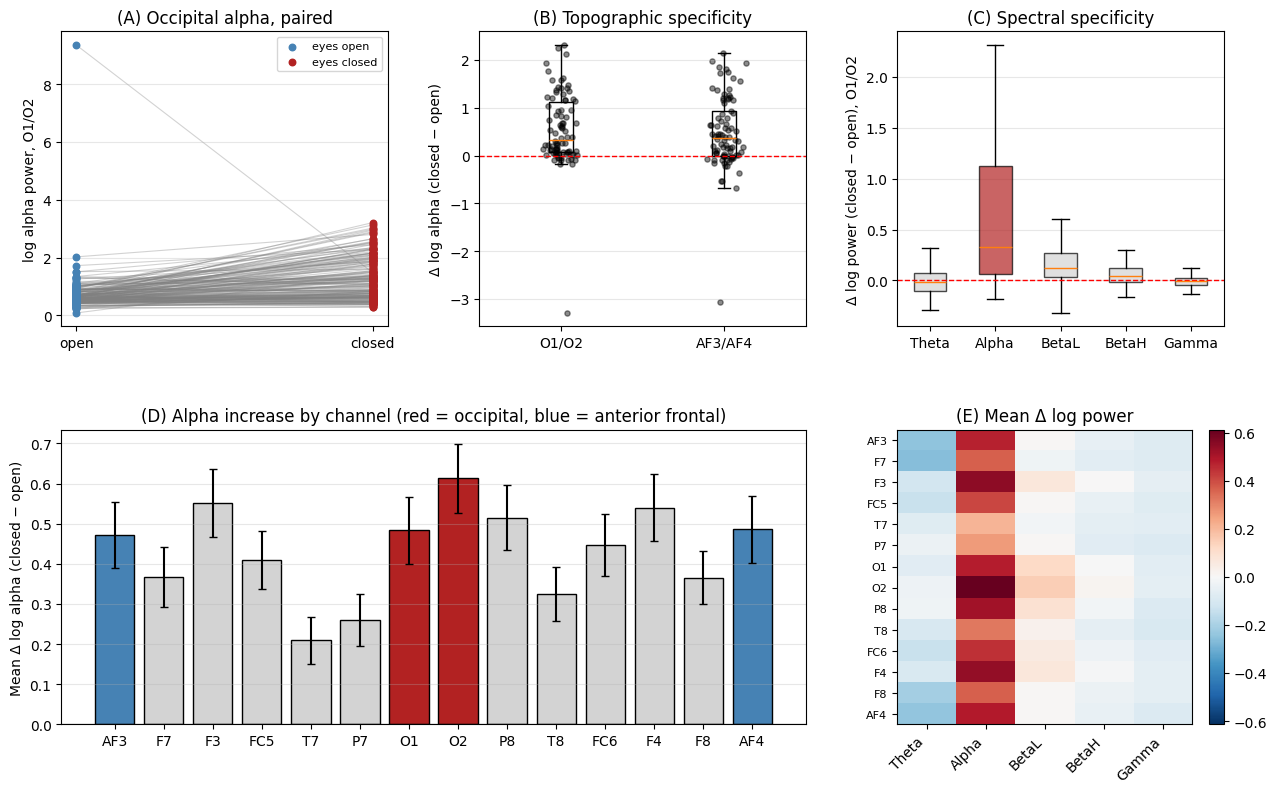

In [8]:
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.28)

# (A) paired open vs closed, occipital alpha
ax = fig.add_subplot(gs[0, 0])
open_vals, closed_vals = [], []
for label, (t_open, t_closed) in PAIRS.items():
    for pid in delta.index:
        if pid in task_vectors[t_open] and pid in task_vectors[t_closed]:
            o = np.log1p(task_vectors[t_open][pid][[feat(c, "Alpha") for c in OCCIPITAL]]).mean()
            c = np.log1p(task_vectors[t_closed][pid][[feat(c, "Alpha") for c in OCCIPITAL]]).mean()
            open_vals.append(o); closed_vals.append(c)
for o, c in zip(open_vals, closed_vals):
    ax.plot([0, 1], [o, c], color="gray", alpha=0.35, linewidth=0.8, zorder=1)
ax.scatter(np.zeros(len(open_vals)), open_vals, color="steelblue", s=22, zorder=2, label="eyes open")
ax.scatter(np.ones(len(closed_vals)), closed_vals, color="firebrick", s=22, zorder=2, label="eyes closed")
ax.set_xticks([0, 1]); ax.set_xticklabels(["open", "closed"])
ax.set_ylabel("log alpha power, O1/O2")
ax.set_title("(A) Occipital alpha, paired")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

# (B) delta distribution, occipital vs anterior frontal alpha
ax = fig.add_subplot(gs[0, 1])
ax.boxplot([summary_series["occipital_alpha"].dropna(), summary_series["frontal_alpha"].dropna()],
           labels=["O1/O2", "AF3/AF4"], showfliers=False)
for i, col in enumerate(["occipital_alpha", "frontal_alpha"], start=1):
    y = summary_series[col].dropna()
    ax.scatter(np.random.normal(i, 0.05, len(y)), y, alpha=0.45, s=14, color="black")
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_ylabel("Δ log alpha (closed − open)")
ax.set_title("(B) Topographic specificity")
ax.grid(alpha=0.3, axis="y")

# (C) delta by band at O1/O2
ax = fig.add_subplot(gs[0, 2])
band_data = [summary_series[f"occipital_{b}"].dropna() for b in FREQ_BANDS]
bp = ax.boxplot(band_data, labels=FREQ_BANDS, showfliers=False, patch_artist=True)
for patch, b in zip(bp["boxes"], FREQ_BANDS):
    patch.set_facecolor("firebrick" if b == "Alpha" else "lightgray")
    patch.set_alpha(0.7)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_ylabel("Δ log power (closed − open), O1/O2")
ax.set_title("(C) Spectral specificity")
ax.grid(alpha=0.3, axis="y")

# (D) channel-wise alpha delta
ax = fig.add_subplot(gs[1, :2])
ch_means = [delta[f"d_{ch}_Alpha"].mean() for ch in CHANNELS]
ch_sems = [delta[f"d_{ch}_Alpha"].sem() for ch in CHANNELS]
colors = ["firebrick" if ch in OCCIPITAL else ("steelblue" if ch in ANTERIOR_FRONTAL else "lightgray")
          for ch in CHANNELS]
ax.bar(CHANNELS, ch_means, yerr=ch_sems, color=colors, edgecolor="black", capsize=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean Δ log alpha (closed − open)")
ax.set_title("(D) Alpha increase by channel (red = occipital, blue = anterior frontal)")
ax.grid(alpha=0.3, axis="y")

# (E) channel × band heatmap of mean delta
ax = fig.add_subplot(gs[1, 2])
heat = pd.DataFrame(
    [[delta[f"d_{ch}_{b}"].mean() for b in FREQ_BANDS] for ch in CHANNELS],
    index=CHANNELS, columns=FREQ_BANDS,
)
vmax = np.abs(heat.values).max()
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(FREQ_BANDS))); ax.set_xticklabels(FREQ_BANDS, rotation=45, ha="right")
ax.set_yticks(range(len(CHANNELS))); ax.set_yticklabels(CHANNELS, fontsize=8)
ax.set_title("(E) Mean Δ log power")
fig.colorbar(im, ax=ax, fraction=0.046)

plt.savefig(OUTPUT_DIR / "berger_check.png", dpi=150, bbox_inches="tight")
plt.show()

## Verdict

In [9]:
delta.to_csv(OUTPUT_DIR / "berger_per_participant.csv")
delta_long.to_csv(OUTPUT_DIR / "berger_per_participant_by_pair.csv", index=False)

p1 = tests_df[tests_df["test"].str.startswith("P1")].iloc[0]
p2 = tests_df[tests_df["test"].str.startswith("P2")].iloc[0]
p3 = tests_df[tests_df["test"].str.startswith("P3b")].iloc[0]

log("\n" + "=" * 66)
log("BERGER-EFFECT VALIDITY CHECK — VERDICT")
log("=" * 66)
log(f"\nPairs used:   {list(PAIRS)}")
log(f"Participants: {len(delta)}")

ok1 = (p1["p_two_sided"] < ALPHA_ALPHA) and (p1["median_delta"] > 0)
ok2 = (p2["p_two_sided"] < ALPHA_ALPHA) and (p2["median_delta"] > 0)
ok3 = (p3["p_two_sided"] < ALPHA_ALPHA) and (p3["median_delta"] > 0)

log(f"\n[{'PASS' if ok1 else 'FAIL'}] P1 occipital alpha rises with eye closure: "
    f"median Δ = {p1['median_delta']:+.4f}, r = {p1['rank_biserial']:+.3f}, p = {p1['p_two_sided']:.2e}")
log(f"[{'PASS' if ok2 else 'FAIL'}] P2 rise is posterior-weighted (O1/O2 > AF3/AF4): "
    f"median Δ = {p2['median_delta']:+.4f}, r = {p2['rank_biserial']:+.3f}, p = {p2['p_two_sided']:.2e}")
log(f"[{'PASS' if ok3 else 'FAIL'}] P3 rise is alpha-specific (alpha > other bands): "
    f"median Δ = {p3['median_delta']:+.4f}, r = {p3['rank_biserial']:+.3f}, p = {p3['p_two_sided']:.2e}")

log("\nInterpretation:")
if ok1 and ok2 and ok3:
    log("  All three predictions hold. The device-derived band power is capturing genuine")
    log("  posterior alpha, and the task labels align with the recorded data. The rest of")
    log("  the pipeline rests on sound footing.")
elif ok1:
    log("  The primary Berger effect is present, so the task labelling is broadly correct and")
    log("  the alpha band is real. The topographic and/or spectral specificity is weaker than")
    log("  canonical scalp EEG — expected to some degree with 14 electrodes, device-side")
    log("  filtering and volume conduction, but it should be stated plainly as a limitation")
    log("  rather than glossed over.")
else:
    log("  *** The primary Berger effect is ABSENT. ***")
    log("  This is the single most reliable effect in EEG, and the battery contains the ideal")
    log("  within-subject contrast for it. Its absence points at a labelling, timestamp-")
    log("  alignment or data-quality problem upstream of every analysis in this project.")
    log("  Resolve this before interpreting the NMF components or the sex association.")

log("\nFiles saved:")
for f in ["berger_per_participant.csv", "berger_per_participant_by_pair.csv",
          "berger_tests.csv", "berger_check.png", "berger_summary.txt"]:
    log(f"  {f}")

with open(OUTPUT_DIR / "berger_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))


BERGER-EFFECT VALIDITY CHECK — VERDICT

Pairs used:   ['gyrus_left', 'gyrus_right']
Participants: 86

[PASS] P1 occipital alpha rises with eye closure: median Δ = +0.3331, r = +0.851, p = 7.23e-12
[FAIL] P2 rise is posterior-weighted (O1/O2 > AF3/AF4): median Δ = +0.0413, r = +0.188, p = 1.29e-01
[PASS] P3 rise is alpha-specific (alpha > other bands): median Δ = +0.3086, r = +0.898, p = 4.61e-13

Interpretation:
  The primary Berger effect is present, so the task labelling is broadly correct and
  the alpha band is real. The topographic and/or spectral specificity is weaker than
  canonical scalp EEG — expected to some degree with 14 electrodes, device-side
  filtering and volume conduction, but it should be stated plainly as a limitation
  rather than glossed over.

Files saved:
  berger_per_participant.csv
  berger_per_participant_by_pair.csv
  berger_tests.csv
  berger_check.png
  berger_summary.txt
